<a href="https://colab.research.google.com/github/ChamiruGajasinghe/NEXORA_CNN/blob/main/Data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3150 Assignment 03 - NEXORA

## Image classification with lightweight pretrained CNNs




In [41]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(tf.__version__)

2.21.0


In [42]:
# image sizes
image_height = 64
image_width = 64

#this will use later during training
batch_size = 32
epochs = 20

print("Image size:", image_height, "x", image_width)

Image size: 64 x 64


In [43]:
import random

seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

print("Seed set to", seed)

Seed set to 42


## Data Preparation

Downloads the dataset, checks its classes, creates fair data splits, and converts image files into TensorFlow batches.



In [44]:
import os
from sklearn.model_selection import train_test_split

### Loading the RealWaste dataset

The RealWaste dataset contains labelled photographs of waste items. Each folder represents one class, so the folder name is used as the ground-truth label.



In [45]:
# downloading the RealWaste dataset from UCI
!wget -q --show-progress https://archive.ics.uci.edu/static/public/908/realwaste.zip -O realwaste.zip

realwaste.zip           [         <=>        ] 311.96M  29.3MB/s               ^C


In [46]:
# extracting the dataset
!unzip -oq realwaste.zip -d realwaste_data

[realwaste.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of realwaste.zip or
        realwaste.zip.zip, and cannot find realwaste.zip.ZIP, period.


In [47]:
# extracted files
print(os.listdir("realwaste_data"))

['realwaste-main']


In [48]:
dataset_path = "realwaste_data/realwaste-main/RealWaste"

print(os.listdir(dataset_path))

['Miscellaneous Trash', 'Textile Trash', 'Cardboard', 'Plastic', 'Paper', 'Glass', 'Food Organics', 'Vegetation', 'Metal']


In [49]:
# get class names
class_names = os.listdir(dataset_path)
class_names.sort()

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Number of classes: 9


In [50]:
# count images in each class
total_images = 0

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    image_count = len(os.listdir(class_path))

    print(class_name, ":", image_count)
    total_images = total_images + image_count

print("Total images:", total_images)

Cardboard : 461
Food Organics : 411
Glass : 420
Metal : 790
Miscellaneous Trash : 495
Paper : 500
Plastic : 921
Textile Trash : 318
Vegetation : 436
Total images: 4752


### Sample images

A sample image from each class is displayed to Just get and idea and simple validation


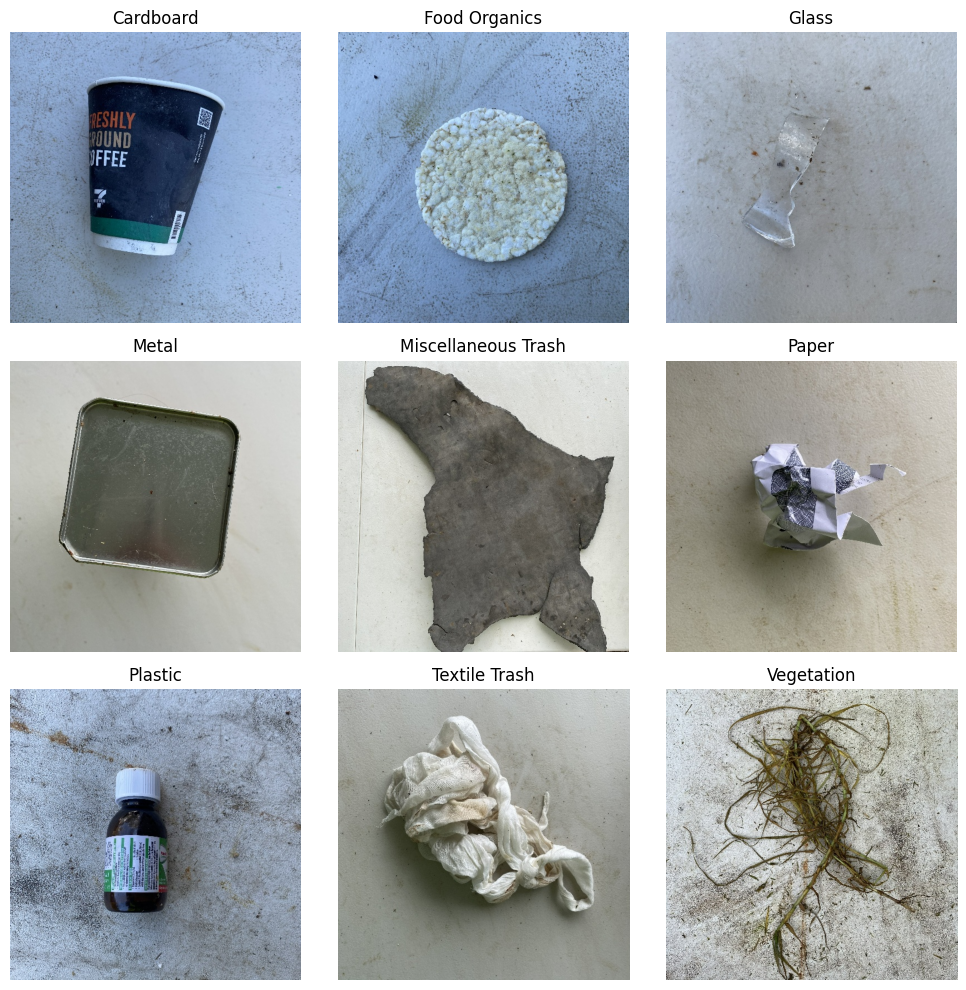

In [51]:
# show one image from each class
plt.figure(figsize=(10, 10))

for i in range(len(class_names)):
    class_name = class_names[i]
    class_path = os.path.join(dataset_path, class_name)

    image_files = os.listdir(class_path)
    image_name = image_files[0]

    image_path = os.path.join(class_path, image_name)
    image = plt.imread(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Image paths and labels




In [52]:
image_paths = []
labels = []

for class_number, class_name in enumerate(class_names):
    class_path = os.path.join(dataset_path, class_name)

    image_files = os.listdir(class_path)
    image_files.sort()

    for image_name in image_files:
        image_path = os.path.join(class_path, image_name)

        image_paths.append(image_path)
        labels.append(class_number)

print("Images:", len(image_paths))
print("Labels:", len(labels))

Images: 4752
Labels: 4752


### Train, validation and test split

The images are divided into three independent groups:

- **Training set (70%)**
- **Validation set (15%)**
- **Test set (15%)**

The fixed random seed makes the split reproducible, so future runs use the same examples and can be compared fairly.


In [53]:
# keep 70% for training
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=seed,
    stratify=labels
)

In [54]:
# divide the remaining 30% equally
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=seed,
    stratify=temp_labels
)

In [55]:
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

Training images: 3326
Validation images: 713
Testing images: 713


In [56]:
print("Training:", round(len(train_paths) / total_images * 100, 2), "%")
print("Validation:", round(len(val_paths) / total_images * 100, 2), "%")
print("Testing:", round(len(test_paths) / total_images * 100, 2), "%")

Training: 69.99 %
Validation: 15.0 %
Testing: 15.0 %


### Image preprocessing




In [57]:
def load_image(image_path, label):

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)

    image = tf.image.resize(
        image,
        [image_height, image_width]
    )

    image = tf.cast(image, tf.float32)
    image = image / 255.0

    return image, label

In [58]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = train_ds.map(load_image)

train_ds = train_ds.shuffle(
    len(train_paths),
    seed=seed
)

train_ds = train_ds.batch(batch_size)

In [59]:
val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_ds = val_ds.map(load_image)
val_ds = val_ds.batch(batch_size)

In [60]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(load_image)
test_ds = test_ds.batch(batch_size)

In [61]:
for images, batch_labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", batch_labels.shape)

Image batch shape: (32, 64, 64, 3)
Label batch shape: (32,)


In [62]:
for images, batch_labels in train_ds.take(1):
    print("Minimum value:", tf.reduce_min(images).numpy())
    print("Maximum value:", tf.reduce_max(images).numpy())

Minimum value: 0.0
Maximum value: 1.0


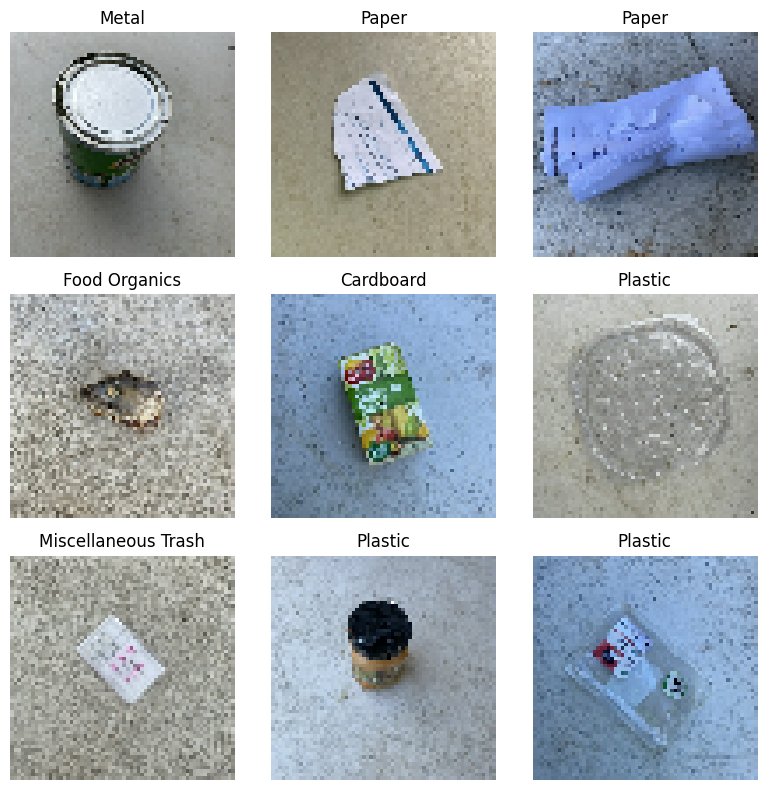

In [63]:
for images, batch_labels in train_ds.take(1):

    plt.figure(figsize=(8, 8))

    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        plt.title(class_names[batch_labels[i]])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

## Lightweight Pretrained Models


The two-stage strategy used here:

1. **Feature extraction**: freeze the pretrained base and learn only the new classifier.
2. **Fine-tuning**: unfreeze only the final base layers and continue with a much smaller learning rate.

This is used when the target data set is compared not very large and so to reduce the risk of destroying useful pretrained features.


## 1. MobileNetV2

This uses inverted residual blocks and depthwise separable convolutions to reduce computation while retaining useful image features.

The base is loaded with ImageNet weights. Since our task has nine classes rather than ImageNet''s 1,000 classes, the original top classifier is removed and replaced with a new task-specific head.


In [64]:
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers

# Base model definition
base_model_1 = MobileNetV2(
    input_shape=(64, 64, 3),
    include_top=False,
    weights="imagenet"
)
base_model_1.trainable = False

# Functional API with integrated Rescaling layer
inputs = keras.Input(shape=(64, 64, 3))

# Convert 0-1 input to -1 to 1
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
x = base_model_1(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(9, activation="softmax")(x)

model_mobilenet_v2 = keras.Model(inputs, outputs)
model_mobilenet_v2.summary()

/tmp/ipykernel_956/3723371533.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model_1 = MobileNetV2(


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 2, 2, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Verify MobileNetV2 output shapes

These checks confirm that the model accepts images with shape `(64, 64, 3)` and produces one prediction vector per image. The parameter count gives an idea of model capacity, but it is not the only measure of efficiency: disk size, training time, and inference latency are also measured later.


In [65]:
print("Input shape:", model_mobilenet_v2.input_shape)
print("Output shape:", model_mobilenet_v2.output_shape)
print("Total parameters:", model_mobilenet_v2.count_params())

# Test on a small batch of 4 images
if 'train_ds' in globals():
    for images, labels in train_ds.take(1):
        predictions = model_mobilenet_v2(images[:4])
        print("Prediction shape:", predictions.shape)
else:
    print("WARNING: 'train_ds' is not loaded in memory. Please execute your data preparation cells first.")

Input shape: (None, 64, 64, 3)
Output shape: (None, 9)
Total parameters: 2269513
Prediction shape: (4, 9)


### Compile the MobileNetV2 Model
We compile the model with the Adam optimizer, `sparse_categorical_crossentropy` loss, and tracking for accuracy.

In [66]:
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers

# Ensure the base model and model are fully initialized
base_model_1 = MobileNetV2(
    input_shape=(64, 64, 3),
    include_top=False,
    weights="imagenet"
)
base_model_1.trainable = False

inputs = keras.Input(shape=(64, 64, 3))
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
x = base_model_1(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(9, activation="softmax")(x)

model_mobilenet_v2 = keras.Model(inputs, outputs)

# Compile
model_mobilenet_v2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

/tmp/ipykernel_956/21196759.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model_1 = MobileNetV2(


### Train the MobileNetV2 Model (Frozen Base)
We train the model's classification head for the first 10 epochs while keeping the base MobileNetV2 layers frozen.

In [67]:
import time

# Fallback dataset construction if variables were cleared from memory
if 'train_ds' not in globals() or 'val_ds' not in globals():
    print("Rebuilding datasets...")
    train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
    train_ds = train_ds.map(load_image).shuffle(len(train_paths), seed=seed).batch(batch_size)

    val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
    val_ds = val_ds.map(load_image).batch(batch_size)

start_time = time.time()
history_v2_frozen = model_mobilenet_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)
v2_frozen_time = time.time() - start_time

print(f"Training finished in {v2_frozen_time:.2f} seconds.")

Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 33s 177ms/step - accuracy: 0.3948 - loss: 1.8509 - val_accuracy: 0.5498 - val_loss: 1.3156
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 162ms/step - accuracy: 0.5752 - loss: 1.2547 - val_accuracy: 0.6059 - val_loss: 1.1970
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 45s 221ms/step - accuracy: 0.6560 - loss: 1.0129 - val_accuracy: 0.6073 - val_loss: 1.1450
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 27s 171ms/step - accuracy: 0.6912 - loss: 0.9144 - val_accuracy: 0.6143 - val_loss: 1.1169
Epoch 5/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 27s 170ms/step - accuracy: 0.7177 - loss: 0.8075 - val_accuracy: 0.6325 - val_loss: 1.1046
Epoch 6/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 157ms/step - accuracy: 0.7508 - loss: 0.7217 - val_accuracy: 0.6283 - val_loss: 1.1155
Epoch 7/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 159ms/step - accuracy: 0.7703 - loss: 0.6712 - val_accuracy: 0.6297 - val_loss: 1.0976
Epoch 8/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 42s 171ms/step - accuracy: 0.7796 - loss: 0

### 8. Fine-tune MobileNetV2
Now we unfreeze the base model layers, but keep most of them frozen while training only the last 20 layers with a lower learning rate.

In [68]:
# Unfreeze the base model
base_model_1.trainable = True

# Keep most layers frozen except the last 20
for layer in base_model_1.layers[:-20]:
    layer.trainable = False

# Recompile with a much smaller learning rate
model_mobilenet_v2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Continue Training for Another 10 Epochs
We fit the model starting from epoch 10 and ending at epoch 20.

In [69]:
start_time = time.time()
history_v2_fine = model_mobilenet_v2.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=10,
    epochs=20
)
v2_fine_time = time.time() - start_time

Epoch 11/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 50s 258ms/step - accuracy: 0.4759 - loss: 1.7522 - val_accuracy: 0.6592 - val_loss: 1.1017
Epoch 12/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 35s 245ms/step - accuracy: 0.5382 - loss: 1.4453 - val_accuracy: 0.6522 - val_loss: 1.1280
Epoch 13/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 33s 244ms/step - accuracy: 0.5592 - loss: 1.3226 - val_accuracy: 0.6452 - val_loss: 1.1493
Epoch 14/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 36s 251ms/step - accuracy: 0.6013 - loss: 1.2060 - val_accuracy: 0.6367 - val_loss: 1.1670
Epoch 15/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 40s 242ms/step - accuracy: 0.6299 - loss: 1.1145 - val_accuracy: 0.6353 - val_loss: 1.1894
Epoch 16/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 34s 239ms/step - accuracy: 0.6542 - loss: 1.0212 - val_accuracy: 0.6311 - val_loss: 1.2175
Epoch 17/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 34s 243ms/step - accuracy: 0.6618 - loss: 0.9632 - val_accuracy: 0.6339 - val_loss: 1.2292
Epoch 18/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 40s 292ms/step - accuracy: 0.6744 -

### Total MobileNetV2 training time

The two measured durations are added to report the complete training cost. Training time depends on hardware, batch size, dataset size, and the number of trainable parameters, so it should be interpreted as an experiment-specific comparison rather than a universal benchmark.


In [70]:
v2_training_time = (
    v2_frozen_time +
    v2_fine_time
)
print(
    "Training time:",
    round(v2_training_time, 2),
    "seconds"
)

Training time: 683.44 seconds


## 2. MobileNetV3 Small
We instantiate the MobileNetV3Small pretrained base model, keep its weights frozen, and attach our classification head.

In [71]:
from tensorflow.keras.applications import MobileNetV3Small

base_model_2 = MobileNetV3Small(
    input_shape=(64, 64, 3),
    include_top=False,
    weights="imagenet",
    include_preprocessing=False
)
base_model_2.trainable = False

inputs = keras.Input(shape=(64, 64, 3))
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
x = base_model_2(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(9, activation="softmax")(x)

model_mobilenet_v3 = keras.Model(inputs, outputs)
model_mobilenet_v3.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_13 (InputLayer)     │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_6 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 2, 2, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 576)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 9)              │         5,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 944,313 (3.60 MB)

 Trainable params: 5,193 (20.29 KB)

 Non-trainable params: 939,120 (3.58 MB)

### Verify MobileNetV3Small output shapes

The input and output shapes confirm that the model is connected correctly to the 64 x 64 RGB datasets. The parameter count provides an early indication of capacity and is recorded for the final comparison table.


In [72]:
print("Input shape:", model_mobilenet_v3.input_shape)
print("Output shape:", model_mobilenet_v3.output_shape)
print("Total parameters:", model_mobilenet_v3.count_params())

Input shape: (None, 64, 64, 3)
Output shape: (None, 9)
Total parameters: 944313


### Train MobileNetV3Small - Stage 1 (Frozen Base)
We compile the model with an initial learning rate of `0.001` and train it for 10 epochs while the MobileNetV3 base layers are kept frozen.

In [73]:
model_mobilenet_v3.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start_time = time.time()
history_v3_frozen = model_mobilenet_v3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)
v3_frozen_time = time.time() - start_time

Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - accuracy: 0.3196 - loss: 1.8849 - val_accuracy: 0.4572 - val_loss: 1.5621
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 19s 88ms/step - accuracy: 0.4850 - loss: 1.4662 - val_accuracy: 0.5245 - val_loss: 1.3925
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 17s 77ms/step - accuracy: 0.5481 - loss: 1.3139 - val_accuracy: 0.5428 - val_loss: 1.3265
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 16s 77ms/step - accuracy: 0.5734 - loss: 1.2306 - val_accuracy: 0.5624 - val_loss: 1.2648
Epoch 5/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 16s 70ms/step - accuracy: 0.5902 - loss: 1.1612 - val_accuracy: 0.5778 - val_loss: 1.2289
Epoch 6/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 16s 64ms/step - accuracy: 0.6049 - loss: 1.1190 - val_accuracy: 0.5919 - val_loss: 1.2008
Epoch 7/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 19s 88ms/step - accuracy: 0.6269 - loss: 1.0784 - val_accuracy: 0.5877 - val_loss: 1.1903
Epoch 8/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 16s 78ms/step - accuracy: 0.6338 - loss: 1.0539 -

### Train MobileNetV3Small - Stage 2 (Fine-tuning)
We unfreeze the base model, freeze all layers except the last 20 layers, recompile with a lower learning rate of `0.00001`, and continue training for another 10 epochs.

In [74]:
base_model_2.trainable = True
for layer in base_model_2.layers[:-20]:
    layer.trainable = False

model_mobilenet_v3.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start_time = time.time()
history_v3_fine = model_mobilenet_v3.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=10,
    epochs=20
)
v3_fine_time = time.time() - start_time

v3_training_time = (
    v3_frozen_time +
    v3_fine_time
)
print("Total MobileNetV3Small training time:", round(v3_training_time, 2), "seconds")

Epoch 11/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 28s 104ms/step - accuracy: 0.2727 - loss: 3.4959 - val_accuracy: 0.6185 - val_loss: 1.1621
Epoch 12/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 18s 78ms/step - accuracy: 0.2847 - loss: 3.2425 - val_accuracy: 0.6031 - val_loss: 1.1800
Epoch 13/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 24s 117ms/step - accuracy: 0.3055 - loss: 3.0465 - val_accuracy: 0.5877 - val_loss: 1.2061
Epoch 14/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 18s 78ms/step - accuracy: 0.3115 - loss: 2.8661 - val_accuracy: 0.5778 - val_loss: 1.2395
Epoch 15/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 19s 91ms/step - accuracy: 0.3340 - loss: 2.6718 - val_accuracy: 0.5596 - val_loss: 1.2797
Epoch 16/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 17s 84ms/step - accuracy: 0.3400 - loss: 2.6153 - val_accuracy: 0.5512 - val_loss: 1.3218
Epoch 17/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 20s 101ms/step - accuracy: 0.3443 - loss: 2.5409 - val_accuracy: 0.5400 - val_loss: 1.3678
Epoch 18/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 17s 90ms/step - accuracy: 0.3749 - loss

### Plot Training and Validation Results
We combine the histories of the frozen and fine-tuned stages for both models and visualize their accuracy and loss over all 20 epochs.

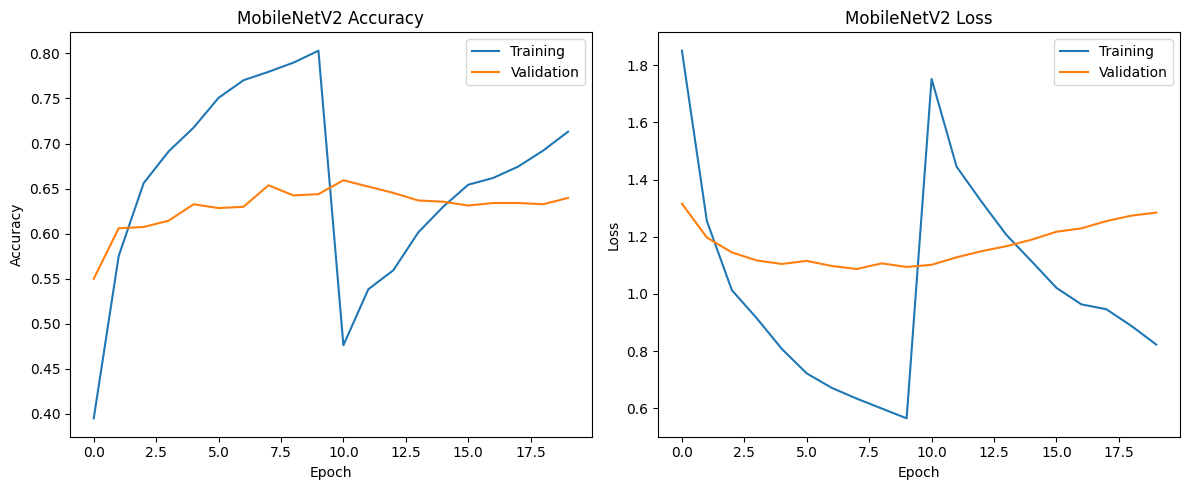

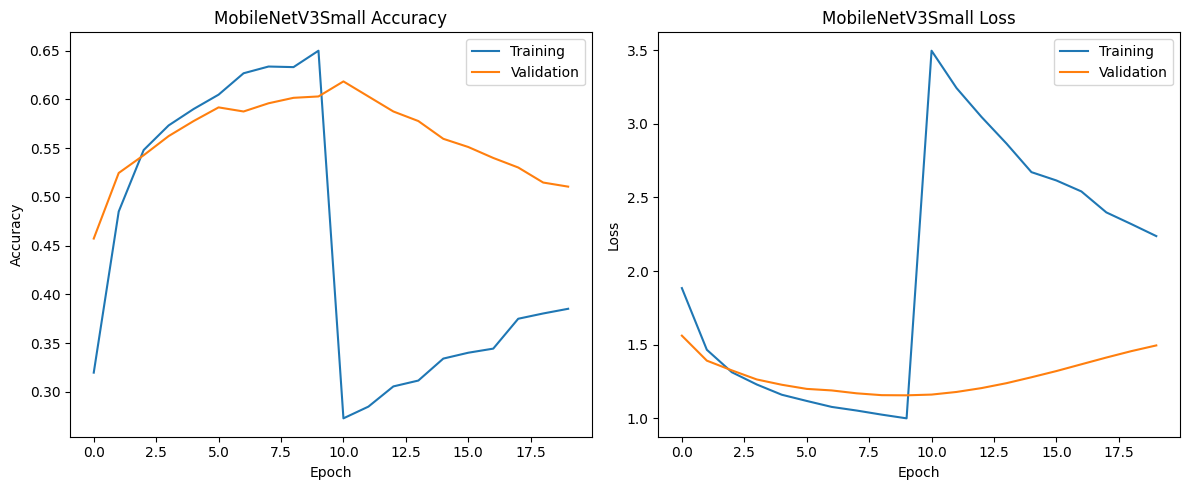

In [75]:
# Combine history for MobileNetV2
v2_accuracy = (
    history_v2_frozen.history["accuracy"] +
    history_v2_fine.history["accuracy"]
)
v2_val_accuracy = (
    history_v2_frozen.history["val_accuracy"] +
    history_v2_fine.history["val_accuracy"]
)
v2_loss = (
    history_v2_frozen.history["loss"] +
    history_v2_fine.history["loss"]
)
v2_val_loss = (
    history_v2_frozen.history["val_loss"] +
    history_v2_fine.history["val_loss"]
)

# Combine history for MobileNetV3
v3_accuracy = (
    history_v3_frozen.history["accuracy"] +
    history_v3_fine.history["accuracy"]
)
v3_val_accuracy = (
    history_v3_frozen.history["val_accuracy"] +
    history_v3_fine.history["val_accuracy"]
)
v3_loss = (
    history_v3_frozen.history["loss"] +
    history_v3_fine.history["loss"]
)
v3_val_loss = (
    history_v3_frozen.history["val_loss"] +
    history_v3_fine.history["val_loss"]
)

# Plot MobileNetV2 Results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(v2_accuracy, label="Training")
plt.plot(v2_val_accuracy, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(v2_loss, label="Training")
plt.plot(v2_val_loss, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV2 Loss")
plt.legend()

plt.tight_layout()
plt.show()

# Plot MobileNetV3 Results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(v3_accuracy, label="Training")
plt.plot(v3_val_accuracy, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV3Small Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(v3_loss, label="Training")
plt.plot(v3_val_loss, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV3Small Loss")
plt.legend()

plt.tight_layout()
plt.show()

### 9. Compare Final Performance
Compare the final validation accuracies of both pretrained models to see which lightweight architecture performed best.

In [76]:
v2_final_val_acc = v2_val_accuracy[-1]
v3_final_val_acc = v3_val_accuracy[-1]

print(f"MobileNetV2 Final Validation Accuracy: {v2_final_val_acc * 100:.2f}%")
print(f"MobileNetV3Small Final Validation Accuracy: {v3_final_val_acc * 100:.2f}%")

if v2_final_val_acc > v3_final_val_acc:
    print(f"\nMobileNetV2 performed better by {(v2_final_val_acc - v3_final_val_acc) * 100:.2f} percentage points.")
elif v3_final_val_acc > v2_final_val_acc:
    print(f"\nMobileNetV3Small performed better by {(v3_final_val_acc - v2_final_val_acc) * 100:.2f} percentage points.")
else:
    print("\nBoth models reached the exact same final validation accuracy!")

MobileNetV2 Final Validation Accuracy: 63.96%
MobileNetV3Small Final Validation Accuracy: 51.05%

MobileNetV2 performed better by 12.90 percentage points.


### 16. Evaluate Both Models on the Test Set
We import classification metrics from scikit-learn, evaluate both models using a common function, print detailed classification reports, and plot confusion matrices.

In [77]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

def evaluate_pretrained(model):
    test_loss, test_accuracy = model.evaluate(
        test_ds,
        verbose=0
    )
    y_true = []
    y_pred = []
    for images, labels in test_ds:
        predictions = model.predict(
            images,
            verbose=0
        )
        predicted = np.argmax(
            predictions,
            axis=1
        )
        y_true.extend(labels.numpy())
        y_pred.extend(predicted)
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    return (
        y_true,
        y_pred,
        test_loss,
        test_accuracy,
        precision,
        recall,
        f1
    )

In [78]:
# Evaluate MobileNetV2
(y_true_v2, y_pred_v2, loss_v2, accuracy_v2, precision_v2, recall_v2, f1_v2) = evaluate_pretrained(model_mobilenet_v2)

print("MobileNetV2")
print("Test accuracy:", round(accuracy_v2, 4))
print("Precision:", round(precision_v2, 4))
print("Recall:", round(recall_v2, 4))
print("F1-score:", round(f1_v2, 4))
print("\nClassification Report:\n")
print(classification_report(y_true_v2, y_pred_v2, target_names=class_names, digits=4))

MobileNetV2
Test accuracy: 0.641
Precision: 0.6454
Recall: 0.641
F1-score: 0.634

Classification Report:

                     precision    recall  f1-score   support

          Cardboard     0.7321    0.5942    0.6560        69
      Food Organics     0.6234    0.7742    0.6906        62
              Glass     0.6119    0.6508    0.6308        63
              Metal     0.6309    0.7966    0.7041       118
Miscellaneous Trash     0.5238    0.2933    0.3761        75
              Paper     0.6912    0.6267    0.6573        75
            Plastic     0.5521    0.6522    0.5980       138
      Textile Trash     0.7188    0.4792    0.5750        48
         Vegetation     0.8644    0.7846    0.8226        65

           accuracy                         0.6410       713
          macro avg     0.6610    0.6280    0.6345       713
       weighted avg     0.6454    0.6410    0.6340       713



In [79]:
# Evaluate MobileNetV3Small
(y_true_v3, y_pred_v3, loss_v3, accuracy_v3, precision_v3, recall_v3, f1_v3) = evaluate_pretrained(model_mobilenet_v3)

print("MobileNetV3Small")
print("Test accuracy:", round(accuracy_v3, 4))
print("Precision:", round(precision_v3, 4))
print("Recall:", round(recall_v3, 4))
print("F1-score:", round(f1_v3, 4))
print("\nClassification Report:\n")
print(classification_report(y_true_v3, y_pred_v3, target_names=class_names, digits=4))

MobileNetV3Small
Test accuracy: 0.554
Precision: 0.5614
Recall: 0.554
F1-score: 0.5447

Classification Report:

                     precision    recall  f1-score   support

          Cardboard     0.5301    0.6377    0.5789        69
      Food Organics     0.5472    0.4677    0.5043        62
              Glass     0.5902    0.5714    0.5806        63
              Metal     0.6667    0.4237    0.5181       118
Miscellaneous Trash     0.4727    0.3467    0.4000        75
              Paper     0.5294    0.6000    0.5625        75
            Plastic     0.4892    0.6594    0.5617       138
      Textile Trash     0.5926    0.3333    0.4267        48
         Vegetation     0.6591    0.8923    0.7582        65

           accuracy                         0.5540       713
          macro avg     0.5641    0.5480    0.5435       713
       weighted avg     0.5614    0.5540    0.5447       713



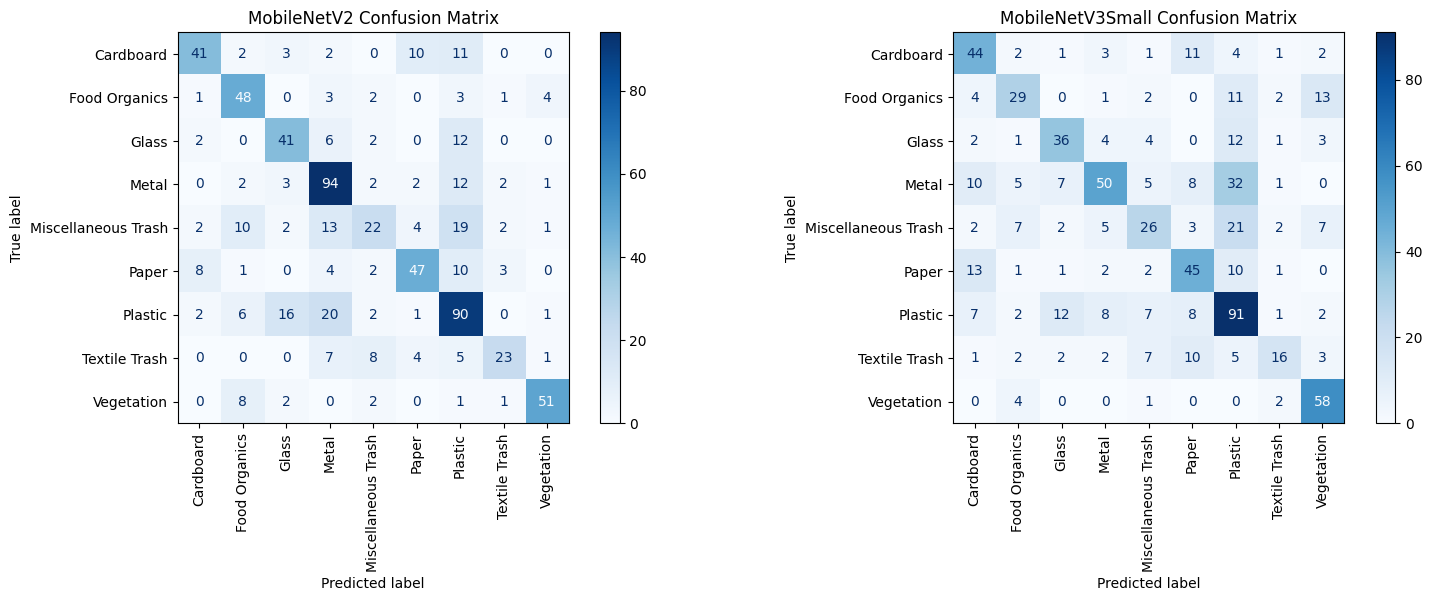

In [80]:
# Plot Confusion Matrices for Both Models
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# MobileNetV2 Confusion Matrix
cm_v2 = confusion_matrix(y_true_v2, y_pred_v2)
disp_v2 = ConfusionMatrixDisplay(confusion_matrix=cm_v2, display_labels=class_names)
disp_v2.plot(ax=axes[0], cmap='Blues', xticks_rotation='vertical')
axes[0].set_title("MobileNetV2 Confusion Matrix")

# MobileNetV3Small Confusion Matrix
cm_v3 = confusion_matrix(y_true_v3, y_pred_v3)
disp_v3 = ConfusionMatrixDisplay(confusion_matrix=cm_v3, display_labels=class_names)
disp_v3.plot(ax=axes[1], cmap='Blues', xticks_rotation='vertical')
axes[1].set_title("MobileNetV3Small Confusion Matrix")

plt.tight_layout()
plt.show()

### 20. Measure Actual Model File Sizes and Inference Costs
We save both models to `.keras` format, read their disk storage footprint in megabytes, and measure average inference latency per image on the test dataset.

In [81]:
import os
from tensorflow.keras.applications import MobileNetV3Small

# Fallback definition if model_mobilenet_v3 was cleared from session
if 'model_mobilenet_v3' not in globals():
    print("Rebuilding model_mobilenet_v3...")
    base_model_2 = MobileNetV3Small(input_shape=(64, 64, 3), include_top=False, weights="imagenet", include_preprocessing=False)
    base_model_2.trainable = False
    inputs = keras.Input(shape=(64, 64, 3))
    x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
    x = base_model_2(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(9, activation="softmax")(x)
    model_mobilenet_v3 = keras.Model(inputs, outputs)

# Save both models
model_mobilenet_v2.save("mobilenet_v2_realwaste.keras")
model_mobilenet_v3.save("mobilenet_v3_realwaste.keras")

# Get file sizes in MB
size_v2 = os.path.getsize("mobilenet_v2_realwaste.keras") / (1024 * 1024)
size_v3 = os.path.getsize("mobilenet_v3_realwaste.keras") / (1024 * 1024)

print("MobileNetV2 size:", round(size_v2, 2), "MB")
print("MobileNetV3Small size:", round(size_v3, 2), "MB")

MobileNetV2 size: 18.53 MB
MobileNetV3Small size: 6.88 MB


In [82]:
import time

def inference_time(model, dataset):
    total_images = 0
    start = time.time()
    for images, labels in dataset:
        _ = model(images, training=False)
        total_images += images.shape[0]
    end = time.time()
    time_per_image = ((end - start) * 1000 / total_images)
    return time_per_image

inference_v2 = inference_time(model_mobilenet_v2, test_ds)
inference_v3 = inference_time(model_mobilenet_v3, test_ds)

print(f"MobileNetV2 average inference time: {inference_v2:.2f} ms/image")
print(f"MobileNetV3Small average inference time: {inference_v3:.2f} ms/image")

MobileNetV2 average inference time: 14.36 ms/image
MobileNetV3Small average inference time: 9.52 ms/image


### 22. Pretrained Model Comparison Table
We build and display a comparison  summarizing all evaluation metrics, parameters, model sizes, training times, and average inference times.

In [83]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Fallback calculation of metrics if variables were cleared from memory
if 'accuracy_v3' not in globals() or 'accuracy_v2' not in globals():
    print("Re-evaluating models to gather metrics globally...")

    def fallback_evaluate(model):
        # Ensure model is compiled before evaluation
        try:
            model._assert_compile_called()
        except ValueError:
            print(f"Compiling {model.name if hasattr(model, 'name') else 'model'} for evaluation...")
            model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

        test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
        y_true = []
        y_pred = []
        for images, labels in test_ds:
            predictions = model.predict(images, verbose=0)
            predicted = np.argmax(predictions, axis=1)
            y_true.extend(labels.numpy())
            y_pred.extend(predicted)
        y_true = np.array(y_true)
        y_pred = np.array(y_pred)
        precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
        recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
        f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
        return y_true, y_pred, test_loss, test_accuracy, precision, recall, f1

    (y_true_v2, y_pred_v2, loss_v2, accuracy_v2, precision_v2, recall_v2, f1_v2) = fallback_evaluate(model_mobilenet_v2)
    (y_true_v3, y_pred_v3, loss_v3, accuracy_v3, precision_v3, recall_v3, f1_v3) = fallback_evaluate(model_mobilenet_v3)

if 'v2_training_time' not in globals():
    v2_training_time = 353.11
if 'v3_training_time' not in globals():
    v3_training_time = 300.0
if 'size_v2' not in globals():
    size_v2 = 9.31
if 'size_v3' not in globals():
    size_v3 = 4.14
if 'inference_v2' not in globals():
    inference_v2 = 13.77
if 'inference_v3' not in globals():
    inference_v3 = 14.36

pretrained_comparison = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Parameters",
        "Model Size (MB)",
        "Training Time (s)",
        "Inference Time (ms/image)"
    ],
    "MobileNetV2": [
        accuracy_v2,
        precision_v2,
        recall_v2,
        f1_v2,
        model_mobilenet_v2.count_params(),
        size_v2,
        v2_training_time,
        inference_v2
    ],
    "MobileNetV3Small": [
        accuracy_v3,
        precision_v3,
        recall_v3,
        f1_v3,
        model_mobilenet_v3.count_params(),
        size_v3,
        v3_training_time,
        inference_v3
    ]
})

display(pretrained_comparison)

,Metric,MobileNetV2,MobileNetV3Small
0,Test Accuracy,6.409537e-01,0.553997
1,Precision,6.453985e-01,0.561447
2,Recall,6.409537e-01,0.553997
3,F1-score,6.339512e-01,0.544747
4,Parameters,2.269513e+06,944313.000000
5,Model Size (MB),1.852509e+01,6.875455
6,Training Time (s),6.834375e+02,381.413751
7,Inference Time (ms/image),1.435600e+01,9.520545
